<a href="https://colab.research.google.com/github/maliksonmez/arnavutkoy-air-quality-forecast/blob/main/notebooks/07_model_comparison_alerts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 — Model comparison & WHO alert evaluation (Assignment 2)

**Questions**
1. Do non-linear models (Random Forest, XGBoost) beat Ridge, the persistence baseline ("tomorrow = today") and raw CAMS for next-day pollution?
2. How well would the app **warn** about days above the WHO 2021 24-hour guideline (precision / recall / F1)?

**Rules (same as 05)**
- Chronological split: train → 06.07.2025 · validation 07.07–17.12.2025 · test 18.12.2025–16.09.2026.
- Hyper-parameters chosen with 5-fold `TimeSeriesSplit` inside the training data only.
- Model *type* chosen on the validation period. The test period is used **once**, after all choices are fixed (models re-fitted on train+validation).
- Features = experiment E2 of notebook 05: station lags (1, 2, 7 days), meteorology, CAMS today + CAMS for the target day, calendar.
- Regression target: next-day **median** (as in A1). Alert target: next-day **mean**, because WHO guidelines are defined on the 24-hour mean.
- CAMS for the target day: if `data/processed/cams_dayahead_daily.csv` (notebook 06) exists, validation and test days use the forecast that was **really issued the day before** (Copernicus ADS, run 00 UTC, lead 21–44 h). Training days keep the Open-Meteo archive value (ADS keeps only a 3-year archive). So models are trained on archive CAMS and evaluated exactly as they would run in practice. Archive-only results are kept in `docs/figures_a2/archive_*.csv` for comparison.

In [1]:
!pip -q install xgboost

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.metrics import (mean_absolute_error as mae, mean_squared_error,
                             confusion_matrix, precision_score, recall_score, f1_score)
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

DEPO = "https://github.com/maliksonmez/arnavutkoy-air-quality-forecast/raw/main/data/processed/"
YEREL = "../data/processed/"
def oku(ad):
    kaynak = YEREL + ad if os.path.exists(YEREL + ad) else DEPO + ad
    return pd.read_csv(kaynak, parse_dates=["tarih"], index_col="tarih").loc["2023-09-16":"2026-09-16"]

saatlik = oku("arnavutkoy_hourly_merged.csv")
gunluk = oku("arnavutkoy_daily_merged.csv")
yon = saatlik["met_wind_direction_10m"]
gunluk["met_pay_ESE_S"] = ((yon >= 101.25) & (yon < 191.25)).resample("D").mean()

OGR_SON, DOG_BAS, DOG_SON, TEST_BAS = "2025-07-06", "2025-07-07", "2025-12-17", "2025-12-18"
FIG = "../docs/figures_a2/"
os.makedirs(FIG, exist_ok=True)
KIRLETICILER = ["PM10", "PM2_5", "NO2", "SO2"]
WHO = {"PM10": 45, "PM2_5": 15, "NO2": 25}          # µg/m³, 24-hour mean (WHO 2021)
ETIKET = {"PM10": "PM10", "PM2_5": "PM2.5", "NO2": "NO2", "SO2": "SO2"}

# Optional: real day-ahead CAMS (notebook 06)
CAMS_SOURCE = "archive"
da_yol = YEREL + "cams_dayahead_daily.csv"
if os.path.exists(da_yol):
    da = pd.read_csv(da_yol, parse_dates=["date"], index_col="date")
    CAMS_SOURCE = "dayahead"
    print("Day-ahead CAMS found:", da.index.min().date(), "->", da.index.max().date())
print("CAMS source for the target day:", CAMS_SOURCE)

Day-ahead CAMS found: 2025-07-07 -> 2026-09-16
CAMS source for the target day: dayahead


## 1. Features (identical to E2 in notebook 05)

In [3]:
DA_AD = {"PM10": "pm10", "PM2_5": "pm25", "NO2": "no2", "SO2": "so2", "dust": "dust"}

def girdiler(d, k, hedef="medyan"):
    """Row = target day (d+1). Inputs = known at the end of day d + CAMS for day d+1."""
    t = d[f"{k}_{hedef}"]
    X = pd.DataFrame(index=d.index)
    X["L1"] = t
    X["L2"] = t.shift(1).fillna(t)
    X["L7"] = t.shift(6).fillna(t)
    for c in ["met_temperature_2m", "met_relative_humidity_2m", "met_surface_pressure",
              "met_wind_speed_10m", "met_wind_u", "met_wind_v", "met_precipitation", "met_pay_ESE_S"]:
        X[c] = d[c]
    for kaynak in [k] + (["dust"] if k.startswith("PM") else []):
        c = f"cams_{kaynak}_ort"
        X[c + "_bugun"] = d[c]
        X[c + "_yarin"] = d[c].shift(-1)          # archive value for day d+1
        if CAMS_SOURCE == "dayahead":
            # validation/test days: replace with the forecast really issued on day d (lead 21-44 h).
            # Training days (before 07.07.2025) keep the archive value (ADS keeps only 3 years).
            gercek = pd.Series(da[f"cams_da_{DA_AD[kaynak]}_mean"].reindex(d.index + pd.Timedelta(days=1)).values, index=d.index)
            X[c + "_yarin"] = gercek.combine_first(X[c + "_yarin"])
    hedef_gun = d.index + pd.Timedelta(days=1)
    X["pazar"] = (hedef_gun.dayofweek == 6).astype(float)
    X["cumartesi"] = (hedef_gun.dayofweek == 5).astype(float)
    X["ay_sin"] = np.sin(2 * np.pi * hedef_gun.month / 12)
    X["ay_cos"] = np.cos(2 * np.pi * hedef_gun.month / 12)
    y = t.shift(-1)
    X.index = y.index = hedef_gun
    return X, y

## 2. Models and hyper-parameter search (training data only)
- **Ridge:** linear, scaled inputs — simple and interpretable.
- **Random Forest:** averages many decision trees; captures non-linear effects (e.g. wind direction × CAMS) without scaling.
- **XGBoost:** gradient-boosted trees; usually the strongest model on tabular data, but easier to over-fit with ~600 training days.

In [4]:
MODELLER = {
    "Ridge": (lambda **p: make_pipeline(StandardScaler(), Ridge(**p)),
              {"alpha": [0.1, 1, 10, 100, 1000]}),
    "Random Forest": (lambda **p: RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1, **p),
                      {"max_depth": [4, 8, None], "min_samples_leaf": [1, 5, 15], "max_features": [0.5, 1.0]}),
    "XGBoost": (lambda **p: XGBRegressor(n_estimators=400, subsample=0.8, colsample_bytree=0.8,
                                         random_state=0, n_jobs=-1, verbosity=0, **p),
                {"max_depth": [2, 3, 5], "learning_rate": [0.02, 0.05], "min_child_weight": [1, 5]}),
}

def ayarla_ve_kur(ad, X, y):
    yap, izgara = MODELLER[ad]
    tss = TimeSeriesSplit(n_splits=5)
    en_iyi, en_skor = None, np.inf
    for p in ParameterGrid(izgara):
        s = np.mean([mae(y.iloc[va], yap(**p).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va]))
                     for tr, va in tss.split(X)])
        if s < en_skor:
            en_iyi, en_skor = p, s
    return yap(**en_iyi).fit(X, y), en_iyi

def calistir(k, hedef, egitim_son, bas, son):
    """Fit all models on data up to `egitim_son`, predict days bas..son. Returns predictions on common days."""
    X, y = girdiler(gunluk, k, hedef)
    tamam = X.notna().all(axis=1) & y.notna()
    Xo, yo = X[tamam].loc[:egitim_son], y[tamam].loc[:egitim_son]
    Xp = X[tamam].loc[bas:son]
    t, params = {}, {}
    t["Persistence"] = Xp["L1"]
    t["Raw CAMS"] = Xp[f"cams_{k}_ort_yarin"]
    for ad in MODELLER:
        m, p = ayarla_ve_kur(ad, Xo, yo)
        t[ad] = pd.Series(m.predict(Xp), index=Xp.index)
        params[ad] = p
    p = pd.DataFrame(t)
    p["actual"] = y.loc[p.index]
    hepsi = y.loc[bas:son]
    return p, params, int(hepsi.notna().sum())

def skorla(p, kapsam):
    rows = {}
    for m in [c for c in p.columns if c != "actual"]:
        rows[m] = {"MAE": mae(p["actual"], p[m]), "RMSE": rmse(p["actual"], p[m])}
    df = pd.DataFrame(rows).T
    df.attrs["days"] = f"{len(p)}/{kapsam}"
    return df

## 3. Validation period — choose the model type

In [5]:
dog, dog_tah, secim, dog_params = {}, {}, {}, {}
for k in KIRLETICILER:
    p, params, n = calistir(k, "medyan", OGR_SON, DOG_BAS, DOG_SON)
    s = skorla(p, n)
    dog[k], dog_tah[k], dog_params[k] = s, p, params
    secim[k] = s.loc[list(MODELLER), "MAE"].idxmin()
    print(f"{ETIKET[k]}  (days {s.attrs['days']})  -> selected: {secim[k]}   params: {params[secim[k]]}")
dog_tablo = pd.concat({ETIKET[k]: dog[k] for k in KIRLETICILER}, axis=1).round(2)
dog_tablo

PM10  (days 144/148)  -> selected: Ridge   params: {'alpha': 1}


PM2.5  (days 147/150)  -> selected: Ridge   params: {'alpha': 10}


NO2  (days 129/134)  -> selected: Ridge   params: {'alpha': 100}


SO2  (days 111/118)  -> selected: Ridge   params: {'alpha': 10}


PM10        PM2.5          NO2          SO2      
                MAE   RMSE   MAE  RMSE    MAE   RMSE   MAE  RMSE
Persistence    7.62  11.50  2.23  3.33   9.89  14.85  1.39  2.04
Raw CAMS       8.80  12.31  3.19  5.26  13.39  16.63  5.12  6.36
Ridge          5.11   7.42  1.95  2.67   5.65   7.79  1.64  2.21
Random Forest  5.58   8.25  2.51  3.42   6.62   8.60  2.03  2.80
XGBoost        5.31   7.72  2.28  3.23   6.66   8.80  2.36  3.11

## 4. Test period — used once
All choices above are now frozen. Every model is re-tuned and re-fitted on train + validation (hyper-parameters again chosen only by `TimeSeriesSplit` inside those data), then predicts the test period.

In [6]:
test, test_tah = {}, {}
for k in KIRLETICILER:
    p, _, n = calistir(k, "medyan", DOG_SON, TEST_BAS, "2026-09-16")
    test[k], test_tah[k] = skorla(p, n), p
    print(f"{ETIKET[k]}  days {test[k].attrs['days']}")
test_tablo = pd.concat({ETIKET[k]: test[k] for k in KIRLETICILER}, axis=1).round(2)
test_tablo

PM10  days 261/265


PM2.5  days 261/265


NO2  days 264/267


SO2  days 263/267


PM10        PM2.5          NO2          SO2      
                 MAE   RMSE   MAE  RMSE    MAE   RMSE   MAE  RMSE
Persistence     9.56  15.24  2.58  3.82   7.50  11.34  1.15  1.65
Raw CAMS       13.02  16.28  4.79  6.06  10.02  12.94  4.86  6.31
Ridge           6.42   9.97  1.94  2.66   6.63   8.83  1.11  1.58
Random Forest   6.41   9.50  1.92  2.65   8.00  10.72  1.18  1.69
XGBoost         6.42   9.77  1.97  2.67   7.79  10.55  1.21  1.72

In [7]:
ozet = []
for k in KIRLETICILER:
    for donem, s in [("Validation", dog[k]), ("Test", test[k])]:
        sec = secim[k]
        ozet.append({"Pollutant": ETIKET[k], "Period": donem, "Days": s.attrs["days"],
                     "Persistence MAE": s.loc["Persistence", "MAE"], "Raw CAMS MAE": s.loc["Raw CAMS", "MAE"],
                     "Ridge MAE": s.loc["Ridge", "MAE"], "RF MAE": s.loc["Random Forest", "MAE"],
                     "XGB MAE": s.loc["XGBoost", "MAE"], "Selected": sec,
                     "Selected RMSE": s.loc[sec, "RMSE"], "Persistence RMSE": s.loc["Persistence", "RMSE"],
                     "Gain vs persistence (MAE %)": 100 * (1 - s.loc[sec, "MAE"] / s.loc["Persistence", "MAE"])})
ozet = pd.DataFrame(ozet).round(2)
ozet.to_csv(FIG + "summary_regression.csv", index=False)
ozet

,Pollutant,Period,Days,Persistence MAE,Raw CAMS MAE,Ridge MAE,RF MAE,XGB MAE,Selected,Selected RMSE,Persistence RMSE,Gain vs persistence (MAE %)
0,PM10,Validation,144/148,7.62,8.80,5.11,5.58,5.31,Ridge,7.42,11.50,32.89
1,PM10,Test,261/265,9.56,13.02,6.42,6.41,6.42,Ridge,9.97,15.24,32.84
2,PM2.5,Validation,147/150,2.23,3.19,1.95,2.51,2.28,Ridge,2.67,3.33,12.39
3,PM2.5,Test,261/265,2.58,4.79,1.94,1.92,1.97,Ridge,2.66,3.82,24.57
4,NO2,Validation,129/134,9.89,13.39,5.65,6.62,6.66,Ridge,7.79,14.85,42.91
5,NO2,Test,264/267,7.50,10.02,6.63,8.00,7.79,Ridge,8.83,11.34,11.54
6,SO2,Validation,111/118,1.39,5.12,1.64,2.03,2.36,Ridge,2.21,2.04,-18.68
7,SO2,Test,263/267,1.15,4.86,1.11,1.18,1.21,Ridge,1.58,1.65,3.65


In [8]:
# How much did using the real day-ahead CAMS change the test results? (archive run saved earlier)
arc_yol = FIG + "archive_summary_regression.csv"
if CAMS_SOURCE == "dayahead" and os.path.exists(arc_yol):
    arc = pd.read_csv(arc_yol)
    kars = (ozet[["Pollutant", "Period", "Ridge MAE", "RF MAE", "XGB MAE"]]
            .merge(arc[["Pollutant", "Period", "Ridge MAE", "RF MAE", "XGB MAE"]], on=["Pollutant", "Period"],
                   suffixes=(" (day-ahead)", " (archive)")))
    display(kars)

,Pollutant,Period,Ridge MAE (day-ahead),RF MAE (day-ahead),XGB MAE (day-ahead),Ridge MAE (archive),RF MAE (archive),XGB MAE (archive)
0,PM10,Validation,5.11,5.58,5.31,5.04,5.36,5.20
1,PM10,Test,6.42,6.41,6.42,6.45,6.48,6.51
2,PM2.5,Validation,1.95,2.51,2.28,1.96,2.51,2.30
3,PM2.5,Test,1.94,1.92,1.97,1.92,1.93,1.99
4,NO2,Validation,5.65,6.62,6.66,5.48,6.50,6.49
5,NO2,Test,6.63,8.00,7.79,6.55,7.66,7.59
6,SO2,Validation,1.64,2.03,2.36,1.65,2.03,2.37
7,SO2,Test,1.11,1.18,1.21,1.11,1.18,1.22


## 5. Error plots (test period)

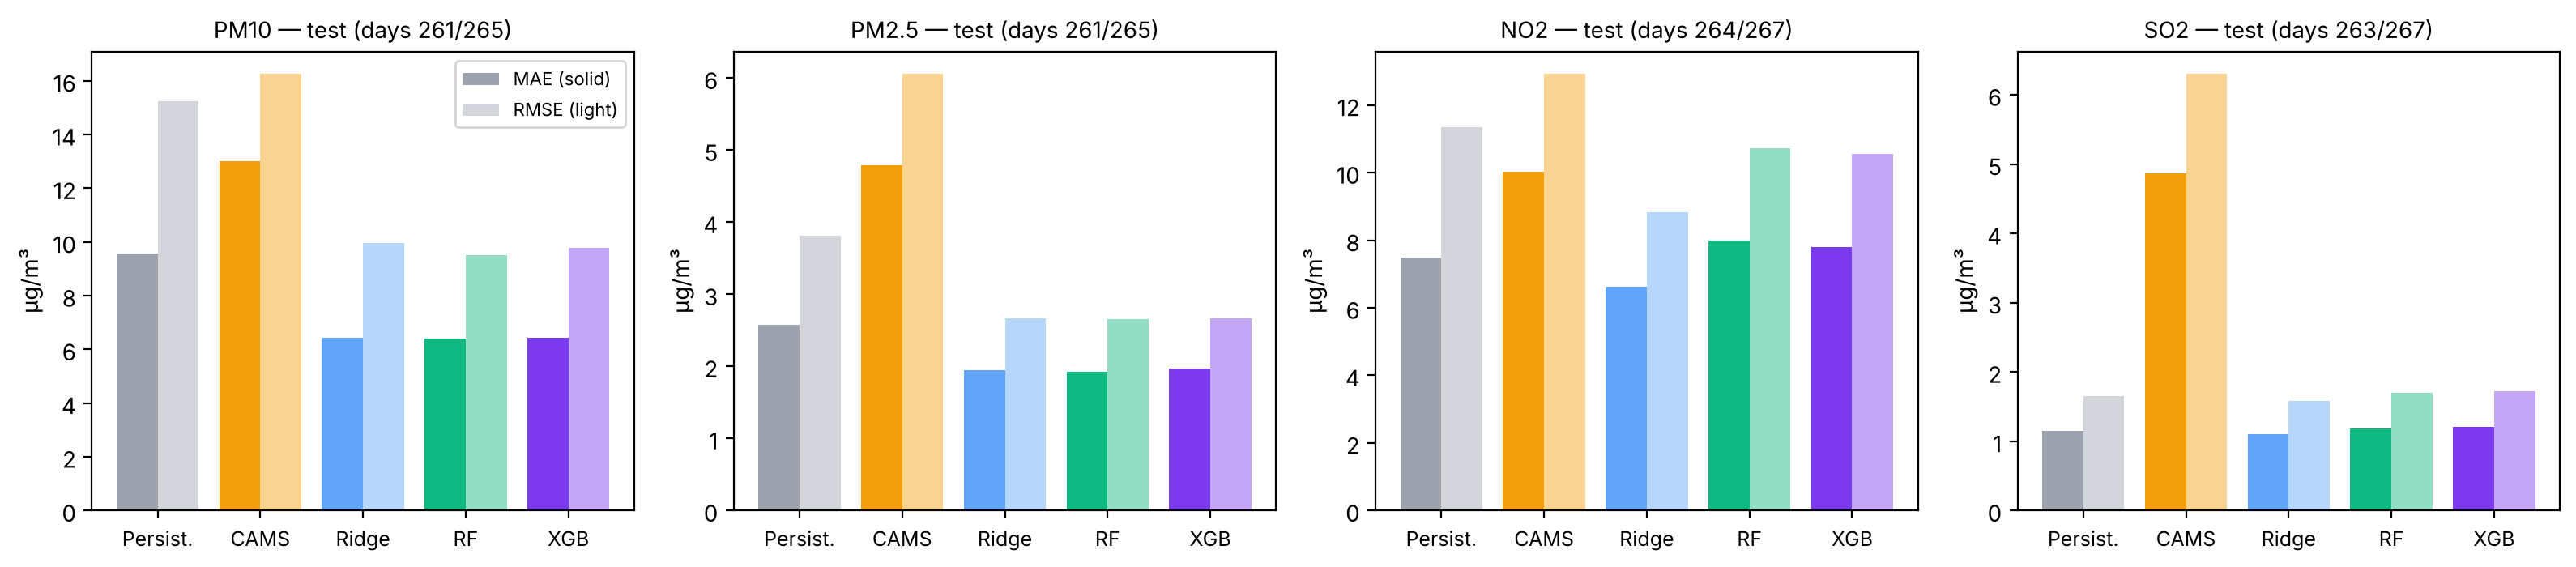

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
renk = {"Persistence": "#9CA3AF", "Raw CAMS": "#F59E0B", "Ridge": "#60A5FA", "Random Forest": "#10B981", "XGBoost": "#7C3AED"}
for ax, k in zip(axes, KIRLETICILER):
    s = test[k]
    x = np.arange(len(s))
    ax.bar(x - 0.2, s["MAE"], 0.4, color=[renk[m] for m in s.index], label="MAE")
    ax.bar(x + 0.2, s["RMSE"], 0.4, color=[renk[m] for m in s.index], alpha=0.45, label="RMSE")
    ax.set_xticks(x); ax.set_xticklabels(["Persist.", "CAMS", "Ridge", "RF", "XGB"], fontsize=9)
    ax.set_title(f"{ETIKET[k]} — test (days {s.attrs['days']})", fontsize=10)
    ax.set_ylabel("µg/m³")
axes[0].legend(["MAE (solid)", "RMSE (light)"], fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "fig_test_errors.png", dpi=200); plt.show()

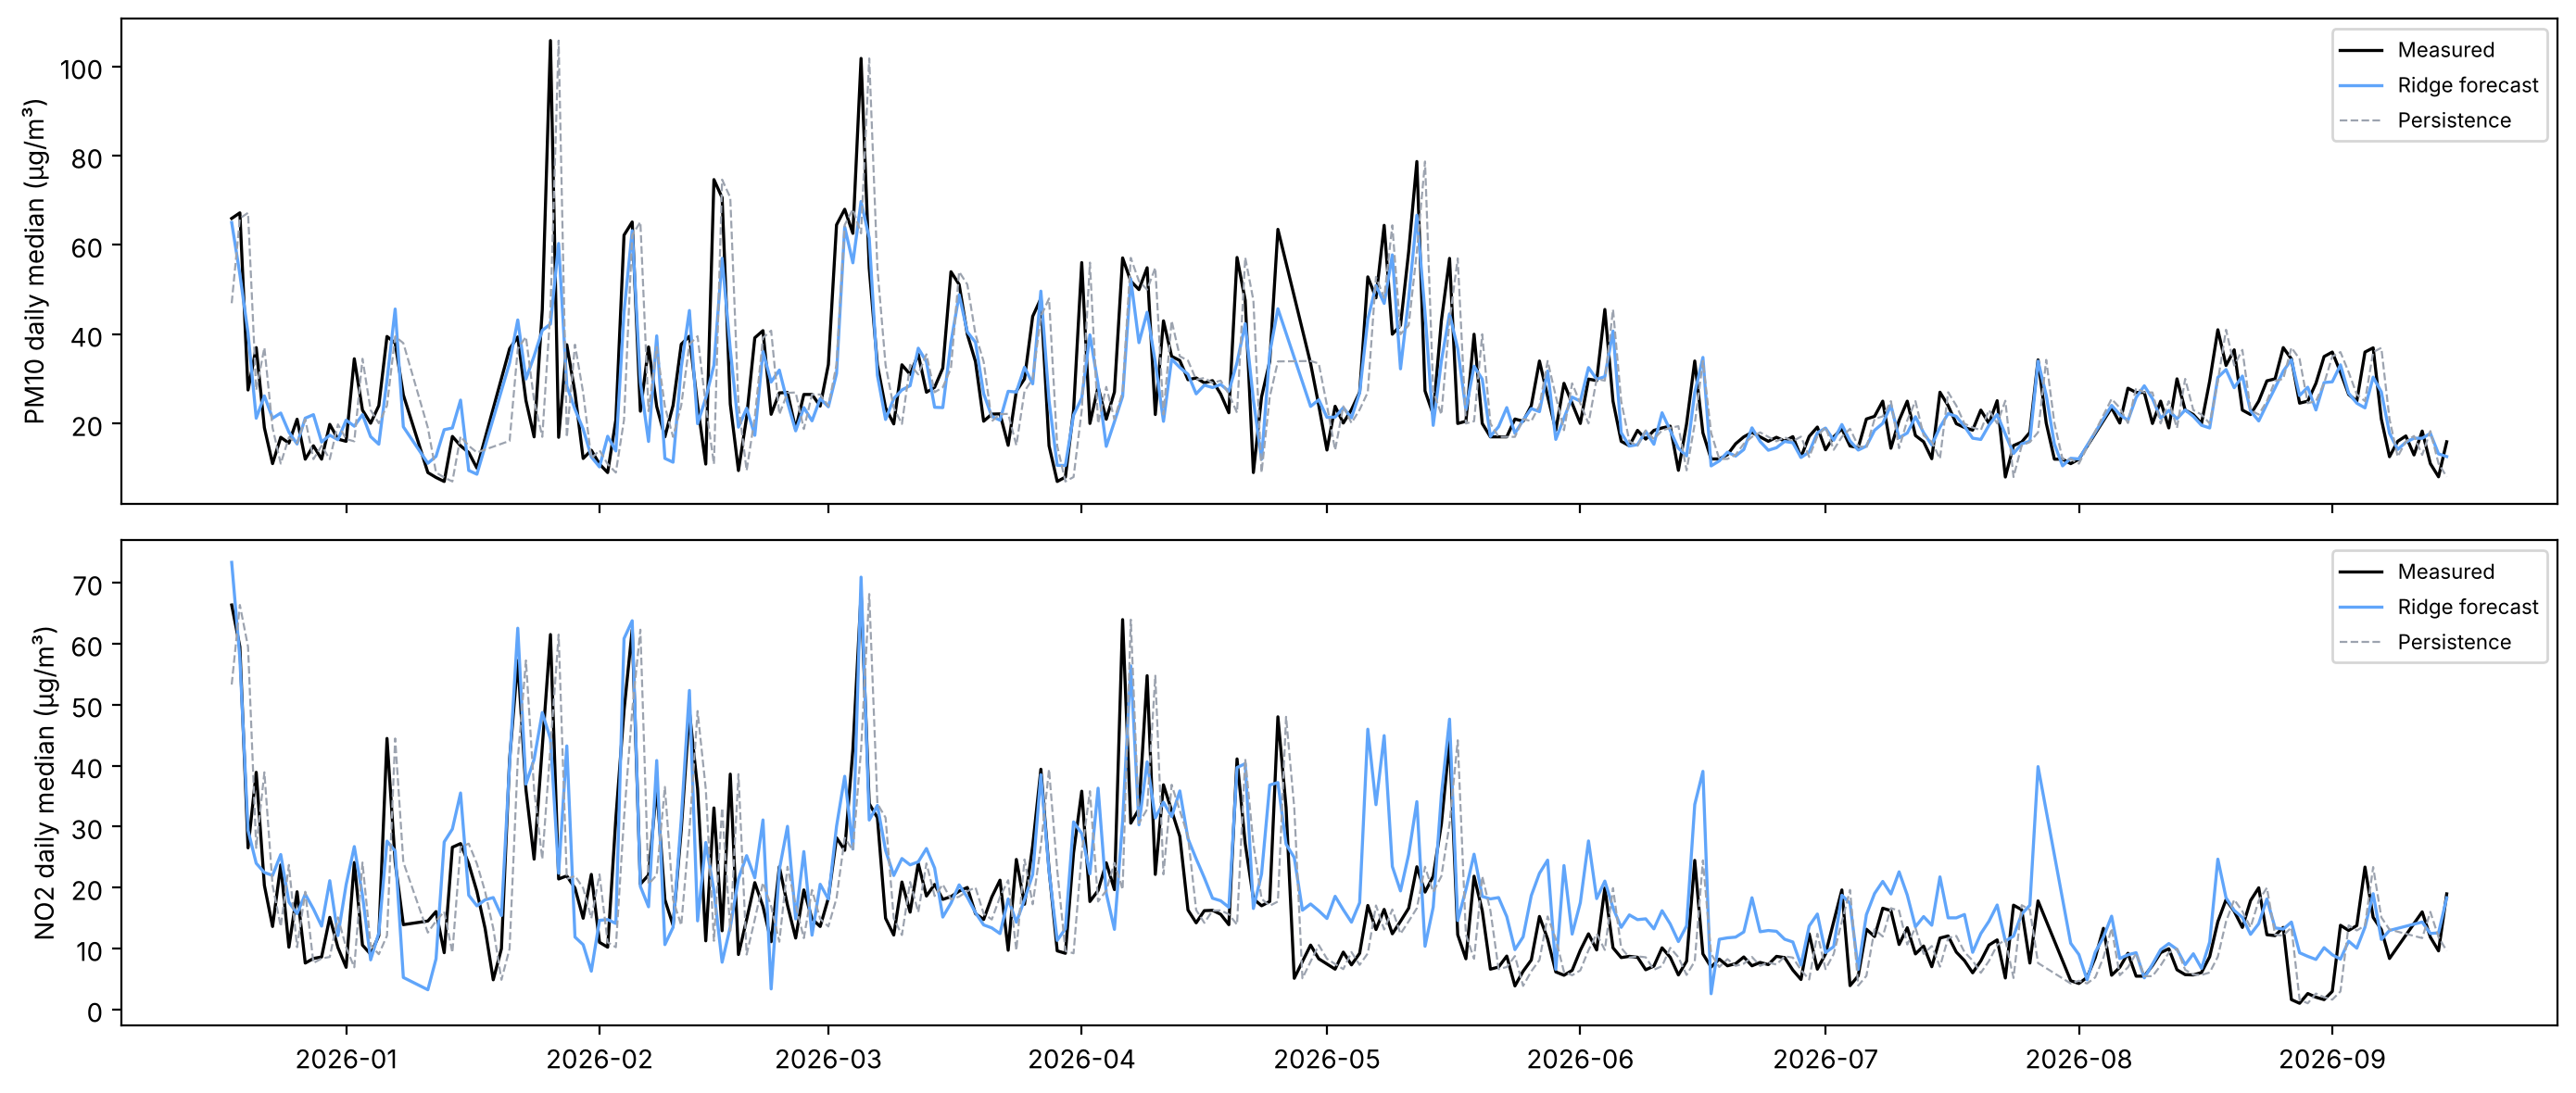

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, k in zip(axes, ["PM10", "NO2"]):
    p = test_tah[k]
    ax.plot(p.index, p["actual"], color="black", lw=1.2, label="Measured")
    ax.plot(p.index, p[secim[k]], color=renk[secim[k]], lw=1.2, label=f"{secim[k]} forecast")
    ax.plot(p.index, p["Persistence"], color="#9CA3AF", lw=0.8, ls="--", label="Persistence")
    ax.set_ylabel(f"{ETIKET[k]} daily median (µg/m³)"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG + "fig_test_timeseries.png", dpi=200); plt.show()

In [11]:
# Error by month (selected model vs persistence) — is the gain stable across seasons?
aylik = {}
for k in KIRLETICILER:
    p = pd.concat([dog_tah[k], test_tah[k]])
    h = p[[secim[k], "Persistence"]].sub(p["actual"], axis=0).abs()
    m = h.groupby(h.index.to_period("M")).mean()
    aylik[ETIKET[k]] = 100 * (1 - m[secim[k]] / m["Persistence"])
aylik = pd.DataFrame(aylik).round(0)
print("Monthly MAE gain of the selected model vs persistence (%), validation + test:")
aylik

Monthly MAE gain of the selected model vs persistence (%), validation + test:


,PM10,PM2.5,NO2,SO2
tarih,,,,
2025-07,34.0,13.0,30.0,-9.0
2025-08,-6.0,-19.0,-21.0,7.0
2025-09,29.0,-55.0,29.0,NaN
2025-10,33.0,13.0,53.0,-41.0
2025-11,34.0,21.0,55.0,-14.0
2025-12,40.0,21.0,44.0,-30.0
2026-01,30.0,4.0,30.0,10.0
2026-02,34.0,5.0,41.0,9.0
2026-03,41.0,45.0,47.0,-11.0


## 6. WHO alert evaluation
"Alert" = the forecast of tomorrow's **daily mean** is above the WHO 24-hour guideline. Evaluated against the measured daily mean. SO2 never exceeded its guideline (0/1026 days) and is skipped.

Methods compared: persistence (today's mean above the guideline), raw CAMS, and the model type selected for that pollutant (re-trained on the daily-mean target with the same procedure).

In [12]:
def uyari_metrik(gercek, tahmin, esik):
    g, t = gercek > esik, tahmin > esik
    tn, fp, fn, tp = confusion_matrix(g, t, labels=[False, True]).ravel()
    return {"Exceed days": int(g.sum()), "Alerts": int(t.sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "Precision": precision_score(g, t, zero_division=0), "Recall": recall_score(g, t, zero_division=0),
            "F1": f1_score(g, t, zero_division=0)}

uyari_rows, uyari_tah = [], {}
for k in WHO:
    for donem, (egit, bas, son) in {"Validation": (OGR_SON, DOG_BAS, DOG_SON),
                                     "Test": (DOG_SON, TEST_BAS, "2026-09-16")}.items():
        p, _, n = calistir(k, "ortalama", egit, bas, son)
        uyari_tah[(k, donem)] = p
        for m in ["Persistence", "Raw CAMS", secim[k]]:
            r = uyari_metrik(p["actual"], p[m], WHO[k])
            uyari_rows.append({"Pollutant": ETIKET[k], "Period": donem, "Method": m, "Days": f"{len(p)}/{n}", **r})
uyari = pd.DataFrame(uyari_rows).round(2)
uyari.to_csv(FIG + "summary_alerts.csv", index=False)
uyari

,Pollutant,Period,Method,Days,Exceed days,Alerts,TP,FP,FN,TN,Precision,Recall,F1
0,PM10,Validation,Persistence,144/148,15,13,7,6,8,123,0.54,0.47,0.50
1,PM10,Validation,Raw CAMS,144/148,15,3,2,1,13,128,0.67,0.13,0.22
2,PM10,Validation,Ridge,144/148,15,14,11,3,4,126,0.79,0.73,0.76
3,PM10,Test,Persistence,261/265,40,40,21,19,19,202,0.52,0.52,0.52
4,PM10,Test,Raw CAMS,261/265,40,3,3,0,37,221,1.00,0.08,0.14
5,PM10,Test,Ridge,261/265,40,30,23,7,17,214,0.77,0.57,0.66
6,PM2.5,Validation,Persistence,147/150,17,17,8,9,9,121,0.47,0.47,0.47
7,PM2.5,Validation,Raw CAMS,147/150,17,30,16,14,1,116,0.53,0.94,0.68
8,PM2.5,Validation,Ridge,147/150,17,23,14,9,3,121,0.61,0.82,0.70
9,PM2.5,Test,Persistence,261/265,54,54,33,21,21,186,0.61,0.61,0.61


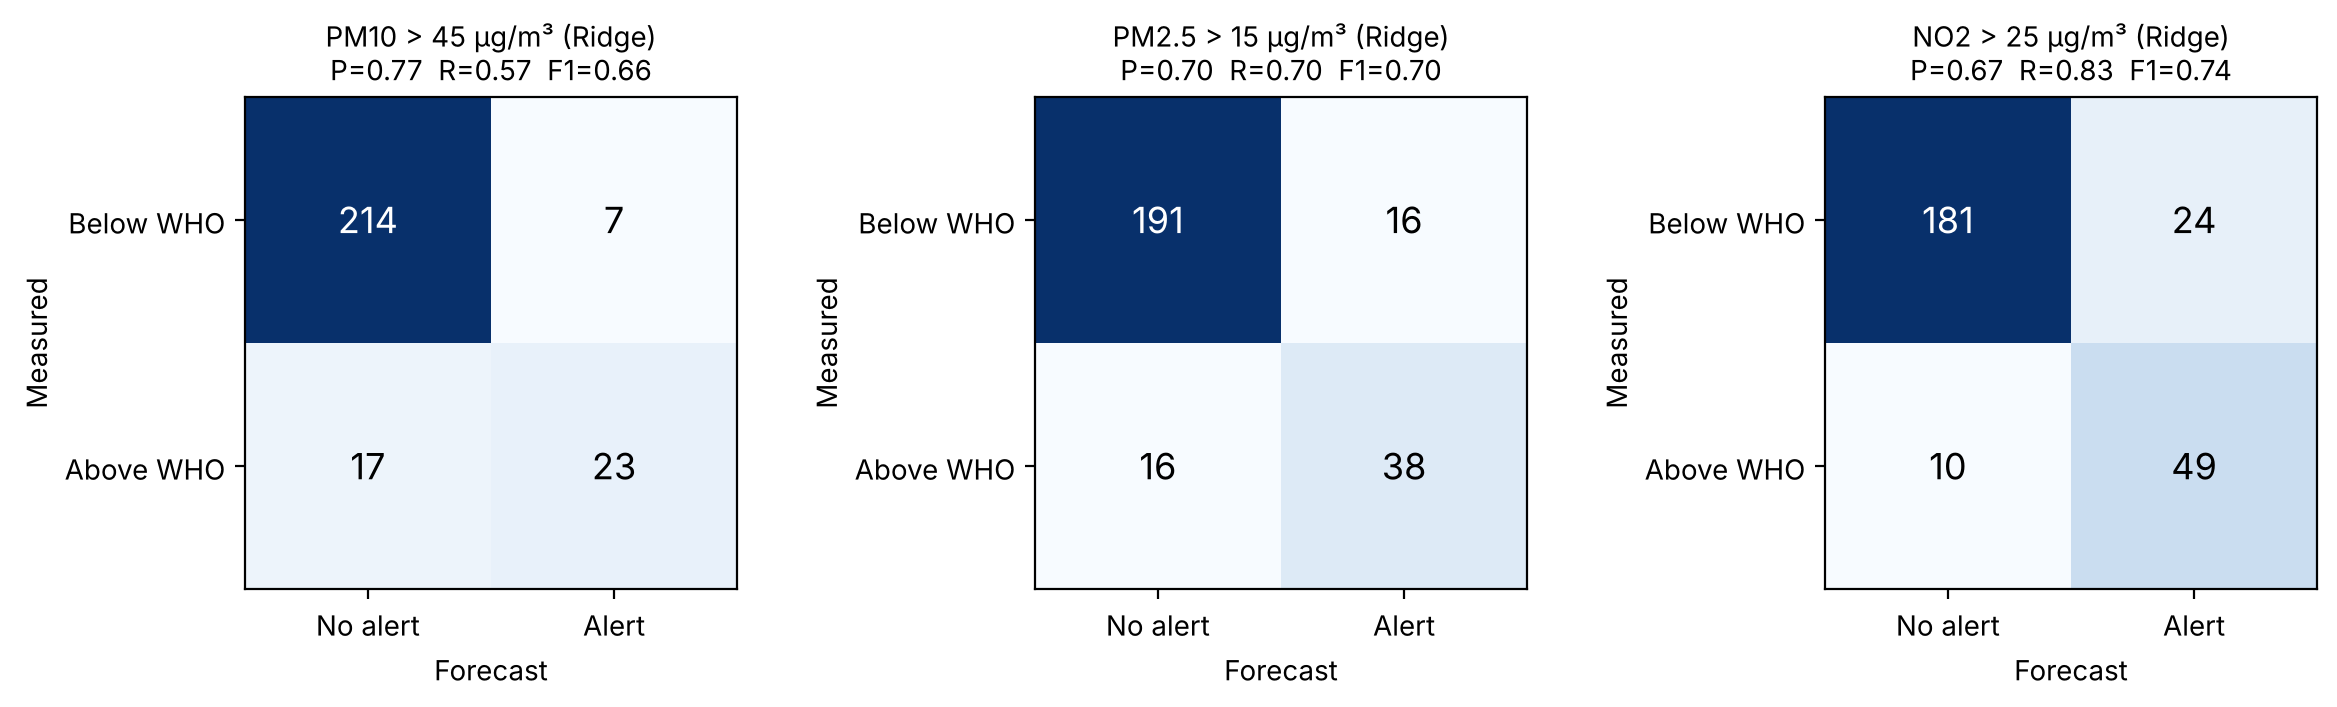

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, k in zip(axes, WHO):
    p = uyari_tah[(k, "Test")]
    cm = confusion_matrix(p["actual"] > WHO[k], p[secim[k]] > WHO[k], labels=[False, True])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No alert", "Alert"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Below WHO", "Above WHO"])
    r = uyari_metrik(p["actual"], p[secim[k]], WHO[k])
    ax.set_title(f"{ETIKET[k]} > {WHO[k]} µg/m³ ({secim[k]})\nP={r['Precision']:.2f}  R={r['Recall']:.2f}  F1={r['F1']:.2f}", fontsize=10)
    ax.set_xlabel("Forecast"); ax.set_ylabel("Measured")
plt.tight_layout(); plt.savefig(FIG + "fig_alert_confusion.png", dpi=200); plt.show()

### Trade-off: alerting earlier (lower decision threshold)
The decision threshold does not have to equal the WHO value. Alerting when the forecast is above e.g. 80 % of the guideline catches more exceedances (recall ↑) but gives more false alarms (precision ↓). For sensitive groups a missed exceedance is worse than a false alarm, so recall may deserve priority. Curves are drawn on the **validation** period (a threshold chosen here could then be checked on new data in A3).

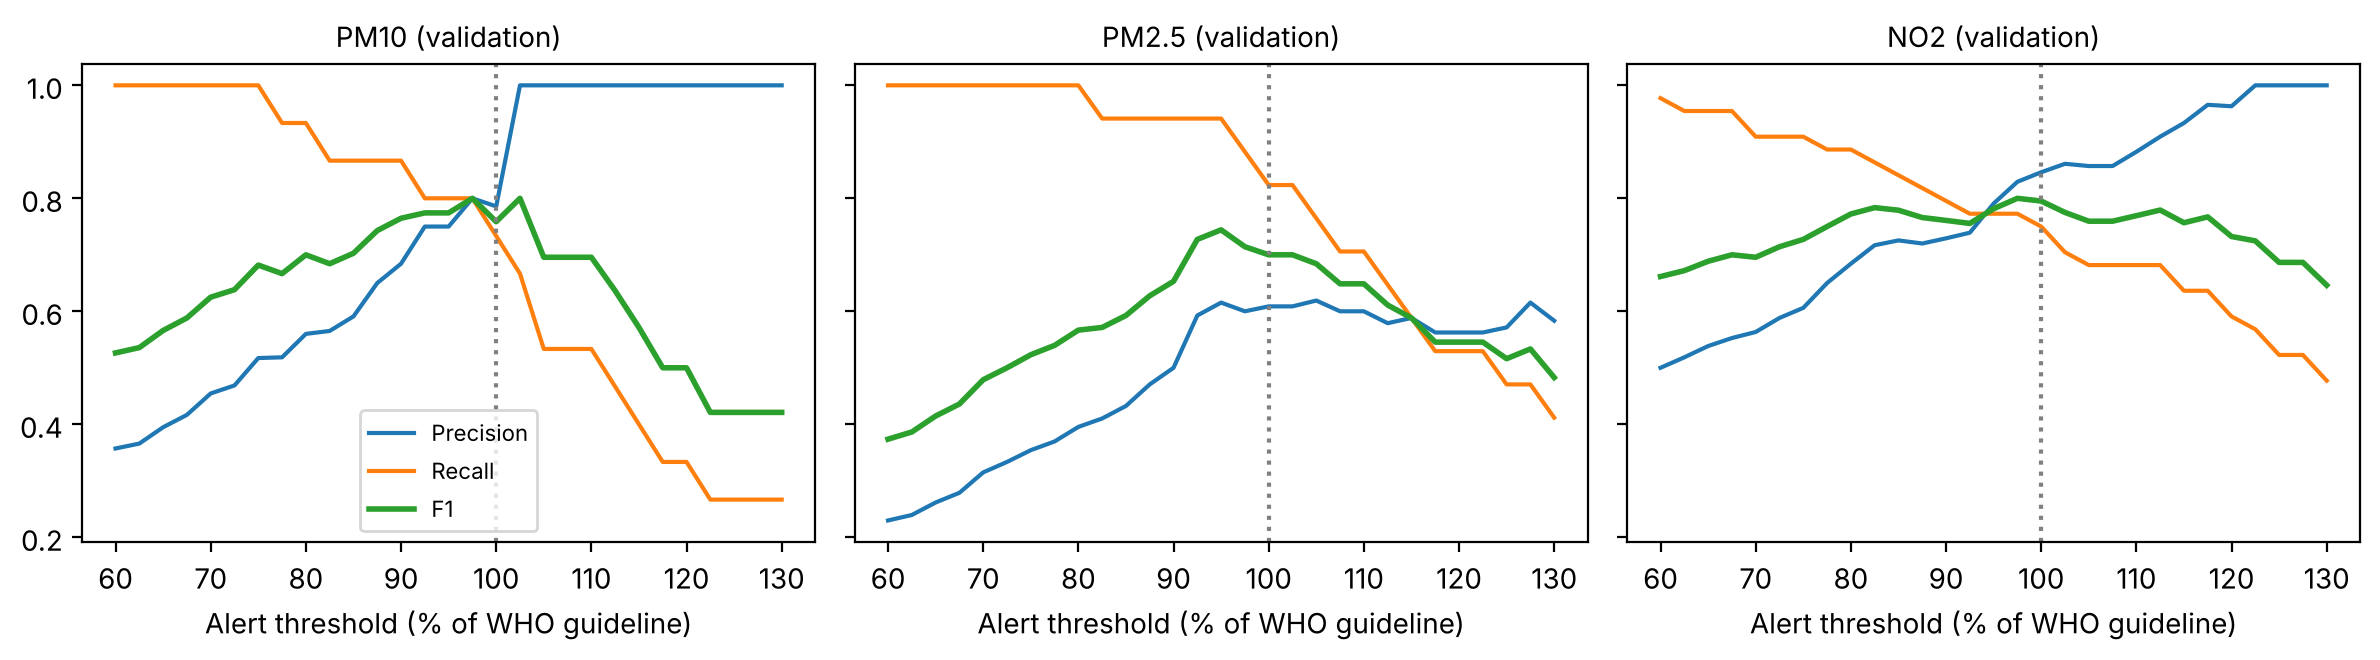

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
oranlar = np.linspace(0.6, 1.3, 29)
for ax, k in zip(axes, WHO):
    p = uyari_tah[(k, "Validation")]
    g = p["actual"] > WHO[k]
    P, R, F = [], [], []
    for o in oranlar:
        t = p[secim[k]] > o * WHO[k]
        P.append(precision_score(g, t, zero_division=0)); R.append(recall_score(g, t, zero_division=0)); F.append(f1_score(g, t, zero_division=0))
    ax.plot(oranlar * 100, P, label="Precision"); ax.plot(oranlar * 100, R, label="Recall"); ax.plot(oranlar * 100, F, label="F1", lw=2)
    ax.axvline(100, color="grey", ls=":")
    ax.set_title(f"{ETIKET[k]} (validation)", fontsize=10); ax.set_xlabel("Alert threshold (% of WHO guideline)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "fig_alert_tradeoff.png", dpi=200); plt.show()

## 7. What drives the selected tree models? (permutation importance, test period)

In [15]:
from sklearn.inspection import permutation_importance
onem = {}
for k in ["PM10", "PM2_5", "NO2"]:
    X, y = girdiler(gunluk, k, "medyan")
    tamam = X.notna().all(axis=1) & y.notna()
    m, _ = ayarla_ve_kur(secim[k], X[tamam].loc[:DOG_SON], y[tamam].loc[:DOG_SON])
    Xt, yt = X[tamam].loc[TEST_BAS:], y[tamam].loc[TEST_BAS:]
    r = permutation_importance(m, Xt, yt, scoring="neg_mean_absolute_error", n_repeats=10, random_state=0)
    onem[ETIKET[k]] = pd.Series(r.importances_mean, index=X.columns)
onem = pd.DataFrame(onem).round(2)
onem.sort_values("NO2", ascending=False).head(8)

,PM10,PM2.5,NO2
cams_NO2_ort_yarin,NaN,NaN,5.36
L1,5.13,1.71,2.68
met_temperature_2m,0.52,0.07,2.08
cams_NO2_ort_bugun,NaN,NaN,1.59
ay_cos,0.31,0.05,0.50
ay_sin,0.41,0.28,0.32
L2,0.02,0.02,0.29
L7,0.15,0.08,0.12
